# analysis_01: a discount factor of its own for the empathic term

Why and how the empathic stream is discounted with its own $\gamma_o$ in `exp6_social_discount`. This
notebook runs no simulation and reads no CSV: its code cells are illustrations on numbers.

**Contents**

1. The objective with two discount factors
2. Consequence: the weight of empathy changes with the horizon
3. Implementation: a two-head DQN
4. Raw or normalised combination
5. Why this is a direct test of the mechanism
6. Conditions
7. Literature

## 1. The objective with two discount factors

With a single $\gamma$, the combined reward $r_i = (1-\alpha_i)\,p_i + \alpha_i\,\tilde e_i$ is discounted as a whole: the
agent cares about its own future and about the others' emotional future **at the same rate**. With two
discount factors, $\gamma_s$ ("self") and $\gamma_o$ ("others"), agent $i$ maximises

$$
G_i = (1-\alpha_i)\sum_{k\ge 0} \gamma_s^{\,k}\, p_i(t+k) \;+\; \alpha_i \sum_{k\ge 0} \gamma_o^{\,k}\, \tilde e_i(t+k).
$$

Since the reward is **linear** in $p$ and $\tilde e$, the action value decomposes exactly:

$$
Q_i(s,a) = (1-\alpha_i)\,Q^{p}_i(s,a) + \alpha_i\,Q^{e}_i(s,a),
$$

where $Q^p$ is the value of the personal stream discounted at $\gamma_s$ and $Q^e$ the value of the empathic
stream discounted at $\gamma_o$. **If $\gamma_o = \gamma_s$, this is exactly the single-$\gamma$ model.**

## 2. Consequence: the weight of empathy changes with the horizon

Seen from time $t$, the relative weight of empathy for an event $k$ steps in the future is

$$
\alpha_{\text{eff}}(k) = \frac{\alpha\,\gamma_o^{\,k}}{(1-\alpha)\,\gamma_s^{\,k} + \alpha\,\gamma_o^{\,k}} .
$$

With $\gamma_o < \gamma_s$, $\alpha_{\text{eff}}(k)$ starts at $\alpha$ for $k=0$ and tends to 0: **the agent is empathic about the
present and selfish about the distant future.**

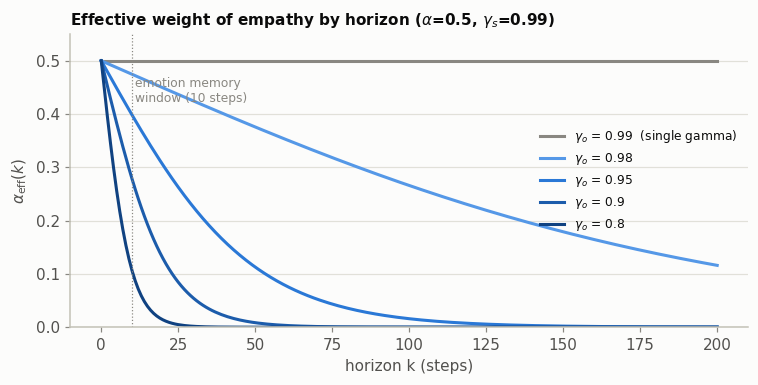

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from analysis_utils import INK, ORDINAL_BLUE, apply_house_style

apply_house_style()

ALPHA = 0.5
GAMMA_SELF = 0.99
GAMMA_OTHERS = [0.99, 0.98, 0.95, 0.9, 0.8]   # 0.99 = single-gamma model

def alpha_eff(k, alpha, g_s, g_o):
    # relative weight of the empathic term for an event k steps ahead
    w_o = alpha * g_o ** k
    w_s = (1 - alpha) * g_s ** k
    return w_o / (w_s + w_o)

k = np.arange(0, 201)
fig, ax = plt.subplots(figsize=(7, 3.6))
colors = [INK["muted"]] + ORDINAL_BLUE[1:]
for g_o, c in zip(GAMMA_OTHERS, colors):
    label = rf"$\gamma_o$ = {g_o}" + ("  (single gamma)" if g_o == GAMMA_SELF else "")
    ax.plot(k, alpha_eff(k, ALPHA, GAMMA_SELF, g_o), color=c, lw=2, label=label)
ax.axvline(10, color=INK["muted"], lw=0.8, ls=":")
ax.text(11, 0.47, "emotion memory\nwindow (10 steps)", color=INK["muted"], fontsize=8, va="top")
ax.set_xlabel("horizon k (steps)")
ax.set_ylabel(r"$\alpha_{\mathrm{eff}}(k)$")
ax.set_title(rf"Effective weight of empathy by horizon ($\alpha$={ALPHA}, $\gamma_s$={GAMMA_SELF})",
             loc="left", fontsize=10, color=INK["primary"])
ax.set_ylim(0, 0.55)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Time inconsistency.** With two different $\gamma$, the relative weight of "me" and "the others" at a given
date depends on the moment from which it is seen, as in hyperbolic discounting. There is no stationary
optimal policy in the strict Bellman sense: the DQN learns the policy of an agent that re-optimises at
each step ("naive" in the time-inconsistency literature), the standard behaviour of multi-horizon
architectures (section 7).

## 3. Implementation: a two-head DQN

A single $\gamma$ cannot reproduce this behaviour by changing the reward alone: the two streams must be
**separated during learning** (`DQNAgent(gamma_others=...)` in `agent_policies_gt_ais.py`).

| Element | Single head | Two heads |
|---|---|---|
| Network output | combined Q | $Q^p$ and $Q^e$ (shared trunk) |
| Replay buffer | $(s, a, r, s', d)$ | $(s, a, p, \tilde e, s', d)$ |
| Greedy action | $\arg\max_a Q$ | $\arg\max_a\,(1-\alpha)Q^p + \alpha Q^e$ |
| TD target | $r + \gamma \max_{a'} Q_{\text{tgt}}(s',a')$ | $y^p = p + \gamma_s Q^p_{\text{tgt}}(s',a^*)$ and $y^e = \tilde e + \gamma_o Q^e_{\text{tgt}}(s',a^*)$ |
| Loss | MSE($Q$, $y$) | MSE($Q^p$, $y^p$) + MSE($Q^e$, $y^e$) |

Both heads bootstrap on **the same action $a^*$**, the one the agent would really play, chosen on the
combined target Q. If each head took its own $\max$, $Q^p$ would be the value of a purely selfish agent,
$Q^e$ that of a purely altruistic one, and their sum would match no real policy (the known pitfall of the
*Hybrid Reward* architecture, van Seijen et al., 2017).

## 4. Raw or normalised combination

A discounted value has a magnitude of order $\frac{\bar r}{1-\gamma}$, so lowering $\gamma_o$ also changes the overall share
of empathy. The heads can be combined in two ways:

- **(a) Raw**: $Q = (1-\alpha)Q^p + \alpha Q^e$. The weight **in the present** stays at $\alpha$.
- **(b) Normalised**: $Q = (1-\alpha)(1-\gamma_s)\,Q^p + \alpha(1-\gamma_o)\,Q^e$. The **total** weight on a constant reward stream
  stays at $\alpha$, and $\gamma_o$ redistributes it over time.

The two coincide when $\gamma_o = \gamma_s$ (a common constant factor) and when $\gamma_o = 0$ (empathy is inert, section 5).

In [2]:
# share of empathy in the total weight, for a constant reward stream of 1, and the alpha' a
# single-gamma agent (= gamma_s) would need to have the same share
for g_o in GAMMA_OTHERS:
    raw_s, raw_o = (1 - ALPHA) / (1 - GAMMA_SELF), ALPHA / (1 - g_o)
    share_raw = raw_o / (raw_s + raw_o)
    print(f"γ_o = {g_o:<5}  share of empathy: raw = {share_raw:5.1%}   normalised = {ALPHA:5.1%}"
          f"   ->  matched α' = {share_raw:.3f}")

γ_o = 0.99   share of empathy: raw = 50.0%   normalised = 50.0%   ->  matched α' = 0.500
γ_o = 0.98   share of empathy: raw = 33.3%   normalised = 50.0%   ->  matched α' = 0.333
γ_o = 0.95   share of empathy: raw = 16.7%   normalised = 50.0%   ->  matched α' = 0.167
γ_o = 0.9    share of empathy: raw =  9.1%   normalised = 50.0%   ->  matched α' = 0.091
γ_o = 0.8    share of empathy: raw =  4.8%   normalised = 50.0%   ->  matched α' = 0.048


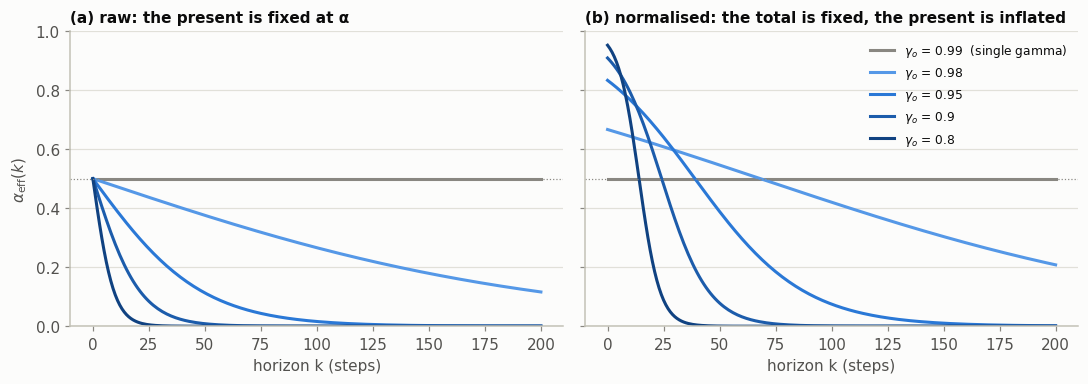

normalised version:
  γ_o = 0.98   α_eff(0) = 66.7%   falls back below α at k ≈ 68.3 steps
  γ_o = 0.95   α_eff(0) = 83.3%   falls back below α at k ≈ 39.0 steps
  γ_o = 0.9    α_eff(0) = 90.9%   falls back below α at k ≈ 24.2 steps
  γ_o = 0.8    α_eff(0) = 95.2%   falls back below α at k ≈ 14.1 steps


In [3]:
def alpha_eff_norm(k, alpha, g_s, g_o):
    # same as alpha_eff, with each head brought back to a mean reward per step
    w_o = alpha * (1 - g_o) * g_o ** k
    w_s = (1 - alpha) * (1 - g_s) * g_s ** k
    return w_o / (w_s + w_o)

def crossover(g_s, g_o):
    # horizon where the normalised version falls back below alpha: (1-g_o)g_o^k = (1-g_s)g_s^k
    return np.log((1 - g_s) / (1 - g_o)) / np.log(g_o / g_s)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, fn, title in [(axes[0], alpha_eff, "(a) raw: the present is fixed at α"),
                      (axes[1], alpha_eff_norm, "(b) normalised: the total is fixed, the present is inflated")]:
    for g_o, c in zip(GAMMA_OTHERS, colors):
        label = rf"$\gamma_o$ = {g_o}" + ("  (single gamma)" if g_o == GAMMA_SELF else "")
        ax.plot(k, fn(k, ALPHA, GAMMA_SELF, g_o), color=c, lw=2, label=label)
    ax.axhline(ALPHA, color=INK["muted"], lw=0.8, ls=":")
    ax.set_title(title, loc="left", fontsize=10, color=INK["primary"])
    ax.set_xlabel("horizon k (steps)")
axes[0].set_ylabel(r"$\alpha_{\mathrm{eff}}(k)$")
axes[0].set_ylim(0, 1.0)
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

print("normalised version:")
for g_o in GAMMA_OTHERS[1:]:
    print(f"  γ_o = {g_o:<5}  α_eff(0) = {alpha_eff_norm(0, ALPHA, GAMMA_SELF, g_o):5.1%}"
          f"   falls back below α at k ≈ {crossover(GAMMA_SELF, g_o):4.1f} steps")

**Reading.** The normalised version makes the agent **hyper-empathic about the immediate** (≈ 91 % at $k=0$
for $\gamma_o = 0.9$), then selfish beyond about 24 steps. The raw version says "same concern for the others
now, fading faster than the concern for oneself": the drop in total weight is the phenomenon itself.
The model uses the **raw** combination.

The confound with $\alpha$ is handled by a **matched-α control**: a single-$\gamma$ agent with an $\alpha'$ giving the
same total share of empathy (column $\alpha'$ above, e.g. $\alpha' \approx 0.09$ for $\gamma_o = 0.9$). Lowering $\alpha$ reduces empathy
uniformly at all horizons, lowering $\gamma_o$ cuts only the future: if the manipulation and its control
differ, the **horizon** of empathy matters, and not only its quantity. The matching is done on a constant
reward stream, so the real share of empathy can differ somewhat.

## 5. Why this is a direct test of the mechanism

**My action at step $t$ has no effect on the others' emotions at step $t$**: an agent's emotion depends only
on its own meals. The only path goes through **the resource**: I eat, the resource falls, the others'
probability of success falls, their emotions fall **later** (and the episode stops earlier at depletion).

As $\gamma_o \to 0$, $Q^e(s,a)$ therefore no longer depends on $a$ and empathy **has no more effect on behaviour**.
$\gamma_o$ is a slider that measures how much horizon empathy needs to produce restraint. Effects of $\alpha$ that
survive down to low $\gamma_o$ go through near consequences. Effects that vanish as soon as $\gamma_o \approx 0.9$ (horizon
≈ 10 steps) need a long horizon, and go through the end of the episode (survival of the resource). Given
the weakness of the link (1 unit out of 500), empathy may be almost inert at low $\gamma_o$.

## 6. Conditions

`make_condition(gamma_others=...)` selects the two-head DQN.

| Group | Conditions | Question |
|---|---|---|
| Empathy horizon | D (sees emotions, $\alpha=0.5$), $\gamma_s = 0.99$, $\gamma_o \in \{0.99, 0.95, 0.9, 0.8, 0\}$ | What empathic horizon is needed to get restraint? |
| $\gamma_o > \gamma_s$ | same with $\gamma_o \in \{0.995, 0.999\}$ | Does an empathy more patient than self-interest strengthen restraint? |
| Matched-α control | D with a single $\gamma$ of 0.99 and $\alpha'$ from `matched_alpha`, one per level other than 0.99 | Does the effect of $\gamma_o$ go beyond a simple "smaller α"? |

## 7. Literature

References to verify before citing them.

- *Several discount factors in one agent*: van Seijen et al. 2017, *Hybrid Reward Architecture*; Romoff
  et al. 2019, *Separating value functions across time-scales*; Fedus et al. 2019, *Hyperbolic
  discounting and learning over multiple horizons*.
- *Social discounting*: Jones & Rachlin 2006 (Psych. Science), discounting by **social distance**, not by
  time.
- *Intertemporal choice for others*: Albrecht et al. 2011 (SCAN) and Ziegler & Tunney 2012 (PLoS ONE) find
  that choices made **for** others are **less** impulsive than for oneself. This is a different question
  (choosing in someone's place, not weighting their future well-being in one's own utility), but a
  reviewer could raise it. The strongest argument for $\gamma_o < \gamma_s$ is **affective empathy**: it responds to
  distress perceived *now* and fades when the distress is no longer perceived.